# EDA05 – London Housing Data



In [1]:
import pandas as pd


In [2]:
data = pd.read_csv('London Housing Data.csv')


In [3]:
data.head()


,date,area,average_price,code,houses_sold,no_of_crimes
0,1/1/1995,city of london,91449,E09000001,17.0,NaN
1,2/1/1995,city of london,82203,E09000001,7.0,NaN
2,3/1/1995,city of london,79121,E09000001,14.0,NaN
3,4/1/1995,city of london,77101,E09000001,7.0,NaN
4,5/1/1995,city of london,84409,E09000001,10.0,NaN


In [4]:
data.shape


(13549, 6)

In [5]:
data.count()


date             13549
area             13549
average_price    13549
code             13549
houses_sold      13455
no_of_crimes      7439
dtype: int64

In [6]:
data.isnull().sum()


date                0
area                0
average_price       0
code                0
houses_sold        94
no_of_crimes     6110
dtype: int64

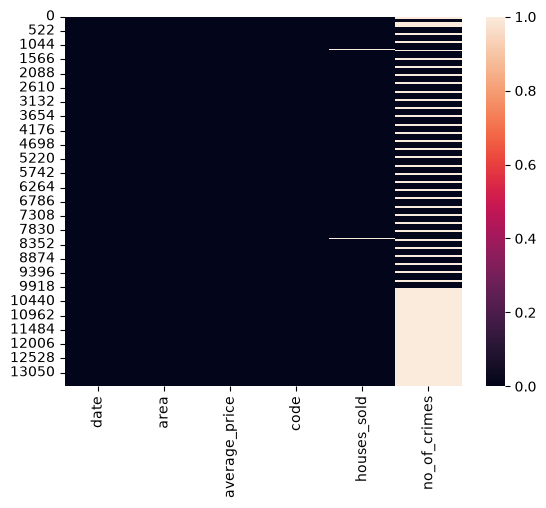

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(data.isnull())
plt.show()


## Q.5-1  Convert the Datatype of 'Date' column to Date-Time format.


In [8]:
data.dtypes


date                 str
area                 str
average_price      int64
code                 str
houses_sold      float64
no_of_crimes     float64
dtype: object

In [9]:
data.date = pd.to_datetime(data.date)


In [10]:
data.dtypes


date             datetime64[us]
area                        str
average_price             int64
code                        str
houses_sold             float64
no_of_crimes            float64
dtype: object

## Q.5-2  Add 'year' column; (2.B) add 'month' as the 2nd column.


In [11]:
data['year'] = data.date.dt.year


In [12]:
data.head(2)


,date,area,average_price,code,houses_sold,no_of_crimes,year
0,1995-01-01,city of london,91449,E09000001,17.0,NaN,1995
1,1995-02-01,city of london,82203,E09000001,7.0,NaN,1995


In [13]:
data.insert(1, 'month', data.date.dt.month)


In [14]:
data.head(2)


,date,month,area,average_price,code,houses_sold,no_of_crimes,year
0,1995-01-01,1,city of london,91449,E09000001,17.0,NaN,1995
1,1995-02-01,2,city of london,82203,E09000001,7.0,NaN,1995


## Q.5-3  Remove the columns 'year' and 'month'.


In [15]:
data.drop(['month', 'year'], axis=1, inplace=True)


In [16]:
data.head(2)


,date,area,average_price,code,houses_sold,no_of_crimes
0,1995-01-01,city of london,91449,E09000001,17.0,NaN
1,1995-02-01,city of london,82203,E09000001,7.0,NaN


## Q.5-4  Show all records where No. of Crimes is 0. How many?


In [17]:
data[data.no_of_crimes == 0]


,date,area,average_price,code,houses_sold,no_of_crimes
72,2001-01-01,city of london,284262,E09000001,24.0,0.0
73,2001-02-01,city of london,198137,E09000001,37.0,0.0
74,2001-03-01,city of london,189033,E09000001,44.0,0.0
75,2001-04-01,city of london,205494,E09000001,38.0,0.0
76,2001-05-01,city of london,223459,E09000001,30.0,0.0
...,...,...,...,...,...,...
178,2009-11-01,city of london,397909,E09000001,11.0,0.0
179,2009-12-01,city of london,411955,E09000001,16.0,0.0
180,2010-01-01,city of london,464436,E09000001,20.0,0.0
181,2010-02-01,city of london,490525,E09000001,9.0,0.0


In [18]:
len(data[data.no_of_crimes == 0])


104

## Q.5-5  Max & min average_price per year in England.


In [19]:
df1 = data[data.area == 'england']


In [20]:
df1['year'] = df1.date.dt.year


In [21]:
df1.groupby('year').average_price.min()


year
1995     52788
1996     52333
1997     55789
1998     61659
1999     65522
2000     75219
2001     84245
2002     96215
2003    121610
2004    139719
2005    158572
2006    166544
2007    181824
2008    165795
2009    159340
2010    174458
2011    173046
2012    174161
2013    176816
2014    188265
2015    202856
2016    220361
2017    231593
2018    240428
2019    243281
2020    247355
Name: average_price, dtype: int64

In [22]:
df1.groupby('year').average_price.max()


year
1995     53901
1996     55755
1997     61564
1998     65743
1999     75071
2000     84191
2001     95992
2002    119982
2003    138985
2004    160330
2005    167244
2006    182031
2007    194764
2008    191750
2009    174136
2010    180807
2011    177335
2012    180129
2013    188544
2014    203639
2015    219582
2016    231922
2017    242628
2018    248620
2019    250410
2020    247355
Name: average_price, dtype: int64

In [23]:
df1.groupby('year').average_price.mean()


year
1995     53322.416667
1996     54151.500000
1997     59160.666667
1998     64301.666667
1999     70070.750000
2000     80814.333333
2001     90306.750000
2002    107981.500000
2003    130218.583333
2004    152314.416667
2005    163570.000000
2006    174351.500000
2007    190025.583333
2008    182379.916667
2009    166558.666667
2010    177472.666667
2011    175230.000000
2012    177488.000000
2013    182581.416667
2014    197771.083333
2015    211174.750000
2016    227337.166667
2017    238161.166667
2018    245018.333333
2019    247101.083333
2020    247355.000000
Name: average_price, dtype: float64

## Q.5-6  Max & min No. of Crimes per area.


In [24]:
data.groupby('area').no_of_crimes.max()


area
barking and dagenham      2049.0
barnet                    2893.0
bexley                    1914.0
brent                     2937.0
bromley                   2637.0
camden                    4558.0
city of london              10.0
croydon                   3263.0
ealing                    3401.0
east midlands                NaN
east of england              NaN
enfield                   2798.0
england                      NaN
greenwich                 2853.0
hackney                   3466.0
hammersmith and fulham    2645.0
haringey                  3199.0
harrow                    1763.0
havering                  1956.0
hillingdon                2819.0
hounslow                  2817.0
inner london                 NaN
islington                 3384.0
kensington and chelsea    2778.0
kingston upon thames      1379.0
lambeth                   4701.0
lewisham                  2813.0
london                       NaN
merton                    1623.0
newham                    3668.0
north

In [25]:
data.groupby('area').no_of_crimes.min().sort_values(ascending=True)


area
city of london               0.0
kingston upon thames       692.0
richmond upon thames       700.0
sutton                     787.0
merton                     819.0
bexley                     860.0
harrow                     937.0
havering                  1130.0
barking and dagenham      1217.0
hammersmith and fulham    1323.0
kensington and chelsea    1347.0
bromley                   1441.0
hillingdon                1445.0
redbridge                 1487.0
greenwich                 1513.0
hounslow                  1529.0
haringey                  1536.0
waltham forest            1575.0
wandsworth                1582.0
enfield                   1635.0
tower hamlets             1646.0
lewisham                  1675.0
barnet                    1703.0
brent                     1850.0
hackney                   1870.0
islington                 1871.0
ealing                    1871.0
croydon                   2031.0
camden                    2079.0
newham                    2130.0
south

## Q.5-7  Count records of each area where average_price < 100000.


In [26]:
data[data.average_price < 100000].area.value_counts()


area
north east              112
north west              111
yorks and the humber    110
east midlands            96
west midlands            94
england                  87
barking and dagenham     85
south west               78
east of england          76
newham                   72
bexley                   64
waltham forest           64
lewisham                 62
havering                 60
greenwich                59
south east               59
croydon                  57
enfield                  54
sutton                   54
hackney                  53
redbridge                52
southwark                48
tower hamlets            47
outer london             46
hillingdon               44
hounslow                 41
lambeth                  41
brent                    40
london                   39
merton                   35
bromley                  33
haringey                 33
ealing                   31
inner london             31
harrow                   30
kingston upon t